## 1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

What it does: This cell imports all the essential data science libraries into the python environment.

Why it needed: Python alone lacks optimization structures needed for fast numerical computation and visualization.

Numpy : the core library for high -performance multidimensioanl array and matrix operations

Pandas : Provides a Dataframe and series structures, which are vital for tabular data manipulation, cleaning anf analysis.

Seaborn and Matplotlib: Used for creating static, interactive, and statistical visualizations. Seaborn is built on top of Matplotlib and makes statistical plotting easier.

Scipy : Used for advanced scientific and technical computing.

## 2.Basic Data Structures

In [2]:
M = np.array(([[1],[2]]))
N= np.array(([[3],[4]]))

What it does: These cells initialize 2-dimensional Numpy arrays(column vectors).

syntax Breakdown : np.array() convert python list into a Numpy array. The nested brackets [[],[]] explicitly create a 2D array with 2 rows and 1 column.

Machine learning context: In ML, data is almost always represented as 2D arrays(matrices) where rows represent individual samples(data points) and columns represent features(variables).

## 3.Data Loading and Exploration

In [3]:
df = sns.load_dataset('iris')
df.info()
df['species'].unique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


array(['setosa', 'versicolor', 'virginica'], dtype=object)

What it does: Loads the dataset directly from the seaborn's online repository and inspects its structure.

load_dataset('iris'): Fetches teh Iris dataset , which contains 150 records of Iris flowers with 4 numeric features(sepal length, sepal width, petal length, petal width) and 1 categorical target(species).

df.info(): A pandas method that returns concise summary od the DataFrame. The output shows 150 enteries, no missing values,4 float64 columns, and 1 object(string) column. this step is critical in machine learning to check for missing data that would crash a model.

df['species'].unique(): Isolate the 'species' column and returns all distinct values. The output['setosa','versicolor','virginica'] confirms there are three classes of flowers in the dataset.

## 4.Machine learning process

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

What it does : Imports specific tools from scikit learn(industry standard machine learning) in python.

train_test_split : Shuffles and split the data

LinearRegression: The algorithm used to find the line of the best fit.

mean_squared_error, r2_score: Mathematical scoring functions to grade the model's accuracy.

# Part1 : How to choose a machine learning model

To choose the right model, answer three core questions:

**1.What is the nature of your target variable(y)?**

**2.What are the characteristics ofn your dataset?**

**3.What are your constarints?**

# What is the nature of your dataset?

Continous and numeric value(e.g predicting house prices, temperature, or petal length ): You need regression models (e.g Linear Regression, Ridge, Random Forest Regressor)

Cetagorical and discrete class(e,g email spam vs not spam, iris species, customer churn): You need Classification models(e.g logistic Regression, Decision trees, Support Vector machines, XGBoost).

No target/ unlabeled Data(e,g customer segmentation): YOu need Clustering or unsupervised models(e,g K-means, PCA)

# What are the characteristics of your dataset?

Dataset size: Small datasets work well with simpler models like Linear/Logistics Regression or Naive Bayes.

Large, complex datasets benefit from deep learning or ensemble methods(Random Forest or XGBoost).

Linearity: If the relationship between features and target is a straight line, linear model excels. If it has complex , non-linear cuurves or interactions, tree based models or neural networks are better.

# What are your constarints?

Interpretability: If stakeholders need to know why a decision was made (e.g. in healthcare and finance ), simpler model like linear REgression or Decsion tree are preferred over "Black box" models like neural networks.

Training speed: If you need real time updates, simpler models train much faster than heany ensemble models.

# Part 2: HOw to choose metrics and their definitions

Metrics are often based on wether you are doing regresion or classification, whether your data has specific quirks(like class imbalance)

# A.Regression metrics(Predicting continous numbers)

**Mean Squared Error:** The average of squared differences between atual values(y) and predicted values(y cap)

--Why use This: Square penalizes larger values heavily, making it useful when large mistakes are especially undesirable.

**Root mean Square error:** The square root of MSE.

--WHy use this: Because MSE is squared, it units dont match your original data . RMSE brings the error metric back to its orginal units of your target variable, making it easier to interpret.

# B.Classification metrics(Predicting categories)

**Accuracy:** The ration of correct predictions to total predictions made.

--Why use this:Great for balanced datasets where every class has roughly an equal number of samples. (Misleading if imbalanced, e.g.99% non-fraudulent transactions

**Precision:** Out of al the instances the model predicted as positive, how many were actually positives?(True Positive / True Positive*False Positive)

--Why use this: Crucial when false positive are costly (e.g. flagging a legitimate email as spam).

**Recall(Sensitivity):** Out of all the  actual positive instances in the dataset, how many did the model manage to find?(True Positives / True Positive+False negatives)

--Why use this: It is crucial when false negative is dangeorus(e.g. medical diagnosis where you cant afford to miss a disease).

**F1-Score:** The harmonic mean to find Precision and Recall.

--Why use this: Provides a single score that balances both precision and recall, espacially valuable when dealing with imbalanced classes.

**ROC-AUC(Receiver operating characteristics-Area under curve):** Measures a models ability to discriminate bate between classes across all the possible classification thresholds.

--Why use this: Given an aggregate measure of performance regardless of what classification threshold is chosen.

In [6]:
x = df[['sepal_length']]
y = df['petal_length']

**What it does:** Separatess the data into an independent variable x(the feature) and a dependent variable y (the target we want to predict).

**Syntax Details:** Notice teh double brackets [[sepal_length]]. This returns 2D pandas dataframe. Scikit learn strictly requires teh feature matrix X to be 2-dimensional (rows=sample and column=features). The single brackets return 1D pandas series, which is the expected format for teh target y.

In [7]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

**What it does:** Split our features and targets into two distinct sets:80% for training the model, and 20% for testing it.

**Why it is needed:** If you test a model on teh exact same data it learned from, you will get a falsely high accuracy(overfitting).

**Test_size:** testing set

**random_state=42:**Sets a seed for the random number generator. Data is shuffled before splitting to prevent biasness. Using a fixed number ensures that everytime you run this notebook, the data is split in the exact same way, ensures reproducibilty.

# 5.Model initializing and Training

In [8]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

**What it does:** Instantiates teh algorithm and computes the optimal mathematical relationship between x_train and y_train.

**Under the hood:** Linear Regression seeks to solve the equation y = beta_0 + beta_1x. The .fit() function uses a method called Ordinary Leats Squares to calculate the intercept(beta_0) and the coefficient/slope(B_1) that minimizes the squared differences between the actual and predicted values.

# 6.Prediction and visualization

In [9]:
y_pred = model.predict(x_test)

**WHat it does:** Feeds the unseen data (20%) of the data(x_test) into the trained model to generate predictions(y_pred). The model applies the y=B_0=B1x formula it just learned to output a forecasted petal length for every given sepal length

In [10]:
predictions = pd.DataFrame({'Actual':y_test, 'Predicted':y_pred})
print(predictions.head(10))

     Actual  Predicted
73      4.7   4.260044
18      1.7   3.526459
118     6.9   7.194384
78      4.5   4.076648
76      4.8   5.543818
31      1.5   2.976270
64      3.6   3.343063
141     5.1   5.727214
68      4.5   4.443440
82      3.9   3.709855


**What it does:** Creates a new DataFrame Comparing the ground truth(y_test) side by side with he models gusses(y_pred). This provides a quick qualitative reality check on the model's performance.

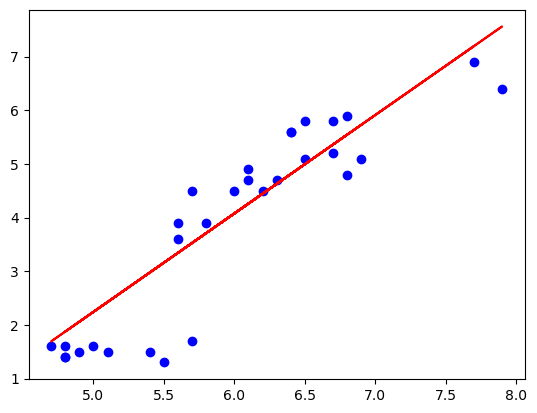

In [11]:
plt.scatter(x_test,y_test,color='blue',label='Actual')
plt.plot(x_test,y_pred,color='red',label='RegressionLine')

**What it does:** Visualoze the results. plt.scatter plots the real test data as dsitinct blue dots. plt.plot draws the model's predictions as a continous red line (the regression line). This viusal confirms trend line appropriately cuts through the center of the data distribustion.

# 7.Quantitaive Evolution

In [12]:
mse =  mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

**What it does:** Quantifies the model's error using the standard statistical metrics.

**Mean Squared Error:** Mathematically defined as 1/n \sigma (y_i - y_i cap)^2. It measures the average squared differences between actual and predicted values. Squaring the errors penalize larger mistakes heavily and ensures negative and positive errors dont cancel each other out. The result was 0.569

**r2:** known as a coefficient of determination. It measures the proprotion of variance in the dependent variable(petal_length)that can be explained by the independent variable (sepal length). The notebook yields an $R^2$ of ~0.818, meaning the model correctly explains approximately 81.8% of the variance in the data. A score closer to 1.0 indicates a highly predictive model. 